**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**15 | Nested Training-Data Scaling: Random Forest and Weighted CNN**

![Stage 15 scientific workflow](../images/15_workflow.svg)

**Objective:** Compare maximum Train sizes of 500 and 1,000 windows per participant for Random Forest and weighted CNN while keeping the six Validation participants and their source windows fixed.

**Dataset:** HARTH v2.0 Development recordings from 29 participants, with nested sampling and S023/S032 excluded. The shared Validation set contains 2,701 windows.

**Notebook Scope:** Verify nesting of Train windows, compare changes in class support and evaluate four model-size conditions on identical Validation rows. This is a Development ablation; equal epoch counts do not imply equal optimiser-update budgets.

**01. Imports and Reusable Research Components**

In [1]:
# =================== 01. Imports and Research Environment ====================

# ------------ 1. Import portable Python and repository path tools ------------
import sys
from pathlib import Path

# ------------ 2. Import numerical and tabular research utilities -------------
import numpy as np
import pandas as pd

# ------------ 3. Import plotting functions for validation figures ------------
import matplotlib.pyplot as plt

# ---------------- 4. Import PyTorch for temporal CNN training ----------------
import torch

# ------------ 5. Display notebook tables and evaluation summaries ------------
from IPython.display import display

# ------------- 6. Import classical Random Forest classification --------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score

# --------- 7. Find the original repository without fixed local paths ---------
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root.parent == root: raise RuntimeError("Open inside the repository.")
    root = root.parent

# ---------- 8. Register original reusable Python module directories ----------
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# --------- 9. Import source-aligned HARTH nested sampling utilities ----------
from harth_data import HARTH_SUBJECTS, SENSOR_COLUMNS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort

# ------------ 10. Import original group split and model functions ------------
from core.data_splitting import split_group_indices
from core.feature_engineering import extract_signal_features
from core.temporal_cnn import train_temporal_cnn
from core.ml_baselines import classification_class_report, evaluate_predictions_by_subject
from core.group_cross_validation import compare_models_by_subject

# -------------------- 11. Report the PyTorch environment ---------------------
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

PyTorch: 2.12.1+cpu | CUDA: False


**02. Construct Strictly Nested Development Windows**

Create label-pure windows independently for each participant and remove out-of-task classes after segmentation. All 500-cap windows remain present in the expanded 1,000-cap cohort; additional positions are selected without class-targeted resampling.

In [2]:
# ================ 02. Build Nested Development Signal Windows ================

# ------------ 1. Exclude both original reserved final Test people ------------
RESERVED_TEST = {"S023", "S032"}

# ---------------- 2. Select exactly the 29 Development people ----------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------- 3. Fix the eight documented activity class codes --------------
TASK_CLASSES = tuple(range(1, 9))

# ----------- 4. Construct label-pure nested signal window cohorts ------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------- 5. Verify all Development people are represented --------------
assert metadata["subject_id"].nunique() == 29

# ---------------- 6. Require complete original Test exclusion ----------------
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ----------------- 7. Check original 500-cap window coverage -----------------
assert overview["base_windows"].sum() == 14201

# ------------ 8. Report the expanded raw source window dimensions ------------
print("Expanded source window array:", X.shape)

# ----------- 9. Inspect sampled windows and provenance per person ------------
display(overview)

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Expanded source window array: (28201, 6, 100)


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500
5,S013,6402,500,1000,500
6,S014,6299,500,1000,500
7,S015,7453,500,1000,500
8,S016,6272,500,1000,500
9,S017,6678,500,1000,500


**03. Keep Validation Participants and Source Rows Fixed**

Reproduce the original split from the 500-window cohort. Both conditions use the same 20 Train participants, six Validation participants and 2,701 Validation windows. The remaining three Development participants are unused.

In [3]:
# ================ 03. Freeze Identical Validation Source Rows ================

# --------------- 1. Locate the original 500-cap source windows ---------------
base_mask = metadata["in_base_500"].to_numpy(dtype=bool)

# ---------------- 2. Recover exact base-cohort row positions -----------------
base_row_ids = np.flatnonzero(base_mask)

# ----------- 3. Recreate the original seeded, subject-level split ------------
original_parts = split_group_indices(
    metadata.iloc[base_row_ids]["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)

# -------------- 4. Record original Train participant identities --------------
train_people = set(metadata.iloc[base_row_ids[original_parts["train"]]]["subject_id"])

# -------------- 5. Preserve all six original Validation people ---------------
validation_people = set(metadata.iloc[base_row_ids[original_parts["validation"]]]["subject_id"])

# --------------- 6. Keep three other Development people unused ---------------
unused_people = set(metadata.iloc[base_row_ids[original_parts["test"]]]["subject_id"])
assert len(train_people) == 20 and len(validation_people) == 6 and len(unused_people) == 3
assert not (train_people & validation_people or train_people & unused_people or validation_people & unused_people)

# --------- 7. Resolve participant IDs for exact source-row matching ----------
person_ids = metadata["subject_id"].to_numpy()

# ----------- 8. Fix original held-out Validation source positions ------------
validation_rows = np.flatnonzero(base_mask & np.isin(person_ids, list(validation_people)))

# ---------------------- 9. Identify 500-cap Train rows -----------------------
base_train_rows = np.flatnonzero(base_mask & np.isin(person_ids, list(train_people)))

# ------------ 10. Include added windows for the same Train people ------------
expanded_train_rows = np.flatnonzero(np.isin(person_ids, list(train_people)))

# ------------- 11. Check strict inclusion of original Train rows -------------
assert np.isin(base_train_rows, expanded_train_rows).all()

# ------------ 12. Require exactly 2701 common Validation windows -------------
assert len(validation_rows) == 2701
print("Train people:", sorted(train_people))
print("Validation people:", sorted(validation_people))
print("Train windows (base/expanded):", len(base_train_rows), len(expanded_train_rows))

# ----------------- 13. Report the protected Validation size ------------------
print("Validation windows (fixed):", len(validation_rows))

Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train people: ['S006', 'S010', 'S013', 'S014', 'S015', 'S017', 'S018', 'S020', 'S024', 'S025', 'S026', 'S027', 'S028', 'S029', 'S030', 'S031', 'S033', 'S034', 'S035', 'S038']
Validation people: ['S009', 'S012', 'S019', 'S022', 'S036', 'S037']
Train windows (base/expanded): 10000 20000
Validation windows (fixed): 2701


**04. Inspect Class Support Added to Train**

Compare the 10,000- and 20,000-window Train sets by activity. Only training support changes; the Validation records, labels and participant identities are held constant.

In [4]:
# ============== 04. Audit Activity Counts in the Two Train Sets ==============

# -------------- 1. Count per-class Train and Validation windows --------------
train_class_counts = pd.DataFrame({
    "base_train": metadata.iloc[base_train_rows]["label"].value_counts(),
    "expanded_train": metadata.iloc[expanded_train_rows]["label"].value_counts(),
    "fixed_validation": metadata.iloc[validation_rows]["label"].value_counts(),
}).reindex(TASK_CLASSES).fillna(0).astype(int)

# -------------- 2. Label only documented HARTH activity classes --------------
train_class_counts.index = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# -------------- 3. Calculate how many windows each class gains ---------------
train_class_counts["new_train_windows"] = (
    train_class_counts["expanded_train"] - train_class_counts["base_train"]
)

# -------- 4. Display observed class increases for the two Train sets ---------
display(train_class_counts)

# ---------- 5. Confirm all classes occur in the original Train set -----------
assert (train_class_counts["base_train"] > 0).all()

# ----------- 6. Confirm nested Train expansion never removes data ------------
assert (train_class_counts["new_train_windows"] >= 0).all()

,base_train,expanded_train,fixed_validation,new_train_windows
1: Walking,2987,5983,453,2996
2: Running,940,1875,78,935
3: Shuffling,169,328,15,159
4: Stairs ascending,156,309,30,153
5: Stairs descending,145,292,32,147
6: Standing,1502,3019,536,1517
7: Sitting,3240,6475,1363,3235
8: Lying,861,1719,194,858


**05. Fit Random Forest at Two Training Sizes**

Apply the same 30 statistical features and Random Forest hyperparameters in both conditions. Evaluate both fits on the fixed Validation windows.

In [5]:
# =============== 05. Fit Random Forest at Two Training Scales ================

# --------- 1. Extract 30 statistics from the same raw signal windows ---------
features = extract_signal_features(X, channel_names=SENSOR_COLUMNS)

# ---------------- 2. Use the documented source activity codes ----------------
y = metadata["label"].to_numpy()

# ----------- 3. Prepare the two matched Random Forest evaluations ------------
rf_predictions = {}

# -------- 4. Train fixed-hyperparameter RF models on both Train sizes --------
for name, train_rows in [("Train 500", base_train_rows), ("Train 1000", expanded_train_rows)]:
    forest = RandomForestClassifier(
        n_estimators=120, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
    forest.fit(features.iloc[train_rows], y[train_rows])
    rf_predictions[name] = forest.predict(features.iloc[validation_rows])
    print(name, "RF Validation Macro F1:",
          round(f1_score(y[validation_rows], rf_predictions[name],
                         labels=TASK_CLASSES, average="macro", zero_division=0), 4))

Input windows: (28201, 6, 100)
Feature matrix: (28201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Train 500 RF Validation Macro F1: 0.8266
Train 1000 RF Validation Macro F1: 0.8644


**06. Train Weighted CNNs on Nested Train Sets**

Fit channel scaling and inverse-square-root class weights separately from each Train set. Keep architecture, seed, epoch count and Validation records constant, while acknowledging that the larger Train set involves more optimiser updates per epoch.

In [6]:
# ================ 06. Train Two Class-Weighted Temporal CNNs =================

# ------------- 1. Prepare CNN predictions and training histories -------------
cnn_predictions, histories = {}, {}

# -------------------- 2. Use the available PyTorch device --------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# -------- 3. Fit Train-weighted CNNs using the two nested Train sets ---------
for name, train_rows in [("Train 500", base_train_rows), ("Train 1000", expanded_train_rows)]:
    print("Weighted CNN:", name)
    model, history, prediction, scaling = train_temporal_cnn(
        X_train=X[train_rows], y_train=y[train_rows],
        X_validation=X[validation_rows], y_validation=y[validation_rows],
        classes=TASK_CLASSES, epochs=5, batch_size=128,
        learning_rate=1e-3, seed=42, device=DEVICE,
        class_weighting="inverse_sqrt",
    )
    cnn_predictions[name] = prediction
    histories[name] = history
    display(history.round(4))

Weighted CNN: Train 500
Epoch 1/5 | loss=0.9723 | validation Macro F1=0.5933
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6236
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7315
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.7968


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.9723,0.5933,0.9374,0.6008
1,2,0.5297,0.6236,0.9397,0.6228
2,3,0.4122,0.6744,0.9482,0.6543
3,4,0.3386,0.7315,0.9415,0.7128
4,5,0.2894,0.7968,0.9534,0.8124


Weighted CNN: Train 1000
Epoch 1/5 | loss=0.7662 | validation Macro F1=0.6385
Epoch 2/5 | loss=0.3719 | validation Macro F1=0.7390
Epoch 3/5 | loss=0.2637 | validation Macro F1=0.8108
Epoch 4/5 | loss=0.2166 | validation Macro F1=0.8428
Epoch 5/5 | loss=0.1793 | validation Macro F1=0.7805


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.7662,0.6385,0.9422,0.6282
1,2,0.3719,0.7390,0.9541,0.7099
2,3,0.2637,0.8108,0.9545,0.7897
3,4,0.2166,0.8428,0.9656,0.8360
4,5,0.1793,0.7805,0.9545,0.8098


**07. Compare Four Conditions on Fixed Validation Data**

Final-epoch Validation Macro F1 was 0.8266 and 0.8644 for Random Forest at 500 and 1,000 windows, and 0.7968 and 0.7805 for weighted CNN. The larger CNN reached 0.8428 at epoch four, but the specified comparison uses final-epoch predictions. This is an observed Development difference, not proof of a causal scaling benefit.

,model,validation_macro_f1,balanced_accuracy,validation_windows
0,RF 500,0.8266,0.8378,2701
1,RF 1000,0.8644,0.8725,2701
2,Weighted CNN 500,0.7968,0.8124,2701
3,Weighted CNN 1000,0.7805,0.8098,2701


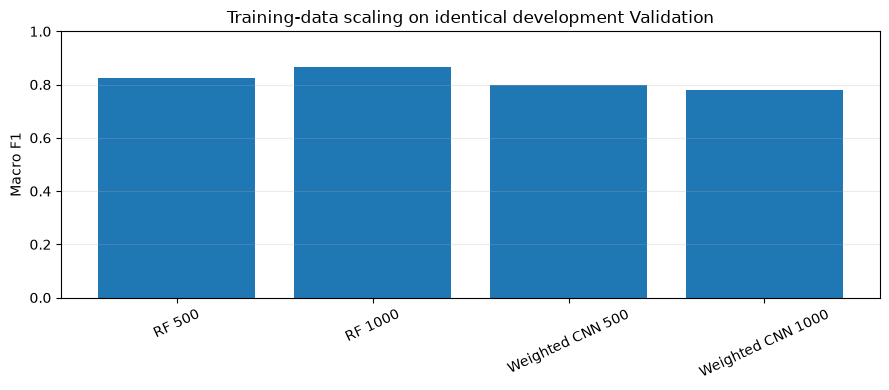

In [7]:
# =============== 07. Compare Four Fixed-Validation Conditions ================

# --------------- 1. Collect four aligned model prediction sets ---------------
prediction_sets = {
    "RF 500": rf_predictions["Train 500"],
    "RF 1000": rf_predictions["Train 1000"],
    "Weighted CNN 500": cnn_predictions["Train 500"],
    "Weighted CNN 1000": cnn_predictions["Train 1000"],
}

# -------- 2. Preserve identical true labels for 2701 Validation rows ---------
y_val = y[validation_rows]

# --------- 3. Calculate Macro F1 and balanced accuracy consistently ----------
results = pd.DataFrame([
    {"model": name, "validation_macro_f1": f1_score(
         y_val, predicted, labels=TASK_CLASSES, average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, predicted),
     "validation_windows": len(y_val)}
    for name, predicted in prediction_sets.items()
])

# ------------ 4. Display all four saved Validation model results -------------
display(results.round(4))

# ------------- 5. Initialise the original four-condition figure --------------
fig, ax = plt.subplots(figsize=(9, 4))

# ----------------- 6. Plot saved fixed-task Macro F1 results -----------------
ax.bar(results["model"], results["validation_macro_f1"])

# ----------------- 7. Label the figure and its metric scale ------------------
ax.set(title="Training-data scaling on identical development Validation",
       ylabel="Macro F1", ylim=(0, 1))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

# --------------- 8. Display the fixed-Validation results chart ---------------
plt.show()

**08. Inspect Class and Participant-Level Changes**

Compare class-specific and paired participant scores using identical Validation support. Random Forest at 1,000 windows scored higher for five of six participants; the larger weighted CNN improved for three and declined for three.

In [8]:
# =============== 08. Inspect Class and Participant F1 Changes ================

# --------- 1. Prepare class-level and participant-level comparisons ----------
class_tables = []
person_tables = []

# ---------- 2. Preserve source identities for six Validation people ----------
val_people_ids = metadata.iloc[validation_rows]["subject_id"].to_numpy()

# ----------- 3. Measure per-class errors for each model condition ------------
for name, predicted in prediction_sets.items():
    class_result = classification_class_report(
        y_val, predicted, classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES]
    )
    class_result["model"] = name
    class_tables.append(class_result)
    person_tables.append(evaluate_predictions_by_subject(
        y_val, predicted, val_people_ids, TASK_CLASSES, name
    ))

# ------------------ 4. Combine all four model class reports ------------------
classes_report = pd.concat(class_tables, ignore_index=True)
people_report = pd.concat(person_tables, ignore_index=True)

# -------------- 5. Display true activity support, recall and F1 --------------
display(classes_report[["model","class","support","precision","recall","f1"]].round(4))

# ------------- 6. Compare signed F1 changes on identical people --------------
for larger, smaller in [("RF 1000","RF 500"), ("Weighted CNN 1000","Weighted CNN 500")]:
    paired, summary = compare_models_by_subject(
        people_report, model_a=larger, model_b=smaller
    )
    display(pd.DataFrame([summary]).round(4))
    display(paired.round(4))

,model,class,support,precision,recall,f1
0,RF 500,Walking,453,0.9320,0.9382,0.9351
1,RF 500,Running,78,0.9750,1.0000,0.9873
2,RF 500,Shuffling,15,0.2500,0.7333,0.3729
3,RF 500,Stairs ascending,30,1.0000,0.3333,0.5000
4,RF 500,Stairs descending,32,1.0000,0.7188,0.8364
5,RF 500,Standing,536,0.9850,0.9832,0.9841
6,RF 500,Sitting,1363,0.9985,0.9956,0.9971
7,RF 500,Lying,194,1.0000,1.0000,1.0000
8,RF 1000,Walking,453,0.9495,0.9536,0.9515
9,RF 1000,Running,78,0.9750,1.0000,0.9873


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,RF 1000,RF 500,macro_f1_fixed_task,6,0.0275,0.025,5,1,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.4324,0.3662,0.0661
1,S012,0.8388,0.8581,-0.0193
2,S019,0.9416,0.9108,0.0309
3,S022,0.8179,0.7516,0.0663
4,S036,0.6203,0.6186,0.0018
5,S037,0.8565,0.8374,0.0192


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,6,0.0134,0.005,3,3,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3182,0.3305,-0.0123
1,S012,0.9173,0.8951,0.0222
2,S019,0.8774,0.8374,0.0401
3,S022,0.8589,0.9012,-0.0422
4,S036,0.5774,0.4823,0.0950
5,S037,0.7557,0.7780,-0.0224


**09. Scientific Quality Gate and Limitations**

Verify nested Train rows, identical Validation source indices, participant separation and reserved Test exclusion. This previously examined Development split cannot establish an independent Test improvement or a general scaling relationship.

In [9]:
# ============= 09. Nested Training-Data Scientific Quality Gate ==============

# ------------ 1. Check the original ten-thousand-window Train set ------------
assert len(base_train_rows) == 10000

# ---------- 2. Check the unchanged held-out Validation window count ----------
assert len(validation_rows) == 2701

# ------------------- 3. Verify nested source-row inclusion -------------------
assert np.isin(base_train_rows, expanded_train_rows).all()

# ---------- 4. Prevent subject overlap between Train and Validation ----------
assert not (set(val_people_ids) & train_people)

# ---------- 5. Exclude both original Test subjects from evaluation -----------
assert not (set(val_people_ids) & RESERVED_TEST)

# ---------------- 6. Confirm four matching prediction vectors ----------------
assert all(len(predicted) == len(y_val) for predicted in prediction_sets.values())

# -------------- 7. Check each reported Macro F1 score is valid ---------------
assert results["validation_macro_f1"].between(0, 1).all()

# --------------- 8. Report the nested-sampling integrity audit ---------------
print("Nested training-data size ablation: PASSED")

# -------- 9. Confirm protected Validation and original Test isolation --------
print("Validation identities and original Test protection: PASSED")

# ----------- 10. Retain the study's scientific evidence limitation -----------
print("Independent full-dataset generalisation: NOT ESTABLISHED")

Nested training-data size ablation: PASSED
Validation identities and original Test protection: PASSED
Independent full-dataset generalisation: NOT ESTABLISHED
